ThickCurr Example: Eddy currents in a conducting torus {#doc_thickcurr_torus_ex}
==========
In this example we use the \ref OpenFUSIONToolkit.ThickCurr.ThickCurr "ThickCurr" python interface to model eddy currents in a solid conducting torus (major radius $R_0 = 1$ m, minor radius $a = 0.5$ m, $\eta = 7 \times 10^{-7} \Omega \cdot m$) at the center of a spherical domain (radius 3 m) bounded by a perfectly conducting wall, with the remainder of the domain treated as vacuum. We will:

 1. Compute the slowest decay times (L/R time constants) of the system with an eigenvalue solve
 2. Simulate the response of the torus to the sudden removal of a uniform vertical magnetic field, using flux loops and a magnetic probe to record the response
 3. Generate plot files of the eigenmodes and time-dependent fields for ParaView

This example follows a similar structure to \ref doc_thickcurr_slab_ex, see that example for additional discussion of the setup and options. Unlike that example, a p-multigrid preconditioner is used, which allows for larger problems than a direct solver.

\note This example takes approximately 20 minutes to run in serial and requires approximately 2.7 GB of memory, with most of the time spent in the eigenvalue solve.

In [1]:
import os
import sys
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize']=(6,4)
plt.rcParams['font.weight']='bold'
plt.rcParams['axes.labelweight']='bold'
plt.rcParams['lines.linewidth']=2
plt.rcParams['lines.markeredgewidth']=2
%matplotlib inline
%config InlineBackend.figure_format = "retina"

### Load ThickCurr library

To load the ThickCurr python module we need to tell python where to the module is located. This can be done either through the `PYTHONPATH` environment variable or within a script using `sys.path.append()` as below, where we look for the environement variable `OFT_ROOTPATH` to provide the path to where the OpenFUSIONToolkit is installed (`/Applications/OFT` on macOS).

For the sensors used below we also import sensor classes from \ref OpenFUSIONToolkit.ThinCurr.sensor "ThinCurr", which can be used with ThickCurr without modification.

In [2]:
oft_python_path = os.getenv('OFT_ROOTPATH')
if oft_python_path is not None:
    sys.path.append(os.path.join(oft_python_path,'python'))
from OpenFUSIONToolkit import OFT_env
from OpenFUSIONToolkit.ThickCurr import ThickCurr
from OpenFUSIONToolkit.ThinCurr.sensor import Mirnov, circular_flux_loop, flux_loop

## Approximate decay time
The slowest decaying mode of this system corresponds to a toroidal current in the torus, which links the hole of the torus. While there is no simple analytic solution for this case, the decay time can be estimated from the inductance and resistance of a torus carrying a uniform toroidal current
$$ L \approx \mu_0 R_0 \left[ ln \left( \frac{8 R_0}{a} \right) - \frac{7}{4} \right], \; R = \frac{2 \eta R_0}{a^2} $$
As the eigenmode adjusts its current distribution to maximize the decay time, the true value is expected to be somewhat larger than this estimate, while the nearby conducting wall reduces the inductance (and decay time) slightly.

In [3]:
mu0 = 4.E-7*np.pi
R0, a, eta = 1.0, 0.5, 7.E-7
L_est = mu0*R0*(np.log(8.0*R0/a)-7.0/4.0)
R_est = 2.0*eta*R0/a**2
print('Estimated decay time = {0:.1f} ms'.format(L_est/R_est*1.E3))

Estimated decay time = 229.5 ms


## Setup model

### Initialize ThickCurr object

In [4]:
myOFT = OFT_env(nthreads=2)
tc_model = ThickCurr(myOFT)

#----------------------------------------------
             ____  ____________
            / __ \/ ____/_  __/
           / / / / /_    / /
          / /_/ / __/   / /
          \____/_/     /_/

Base release:        
Development branch:  claude/optimistic-franklin-n8hrmq
Revision id:         6ddb040

Parallelization Info:
  # of MPI tasks      =    1
  # of NUMA nodes     =    1
  # of OpenMP threads =    2

Linear Algebra backend: native

#----------------------------------------------



### Load mesh and build model
The mesh for this example (`thickcurr_torus.h5`, 12180 cells) is generated using [GMSH](https://gmsh.info/) with the script `create_torus_mesh.py`, which requires the `gmsh` python package. A second-order (curved) mesh is generated to accurately represent the curved surfaces of the torus and outer boundary, so `grid_order=2` is used. The torus is region 2 in the mesh and the vacuum is region 1.

The XML input file (`oft_in.xml`) sets the resistivity of the torus and defines the preconditioner, which is a p-multigrid V-cycle (`type="mg"`) between the second-order (`order=2`) and linear FE levels on the same mesh, enabled with `pmg=True`. On the second-order level the smoother is two iterations of GMRES, preconditioned with block-Jacobi using 200 local blocks, each solved with a direct (LU) solver. On the linear (coarse) level a single block (`nlocal=1`) is used, which corresponds to a direct solve of the full coarse system. Compared to a direct solve of the full system, this approach greatly reduces the required memory and allows larger meshes to be used (eg. a direct solve on a 6337 cell mesh required ~6 GB). Typically, 7-15 GMRES iterations are required per time step.

```xml
<oft>
  <thickcurr>
    <region>
      <id>2</id>
      <eta>7.0E-7</eta>
    </region>
    <pre type="mg">
      <smoother direction="both">
        <solver type="gmres">
          <its>2</its>
          <nrits>2</nrits>
          <pre type="block_jacobi">
            <nlocal>200</nlocal>
            <solver type="lu"></solver>
          </pre>
        </solver>
      </smoother>
      <coarse>
        <solver type="gmres">
          <its>1</its>
          <nrits>1</nrits>
          <pre type="block_jacobi">
            <nlocal>1</nlocal>
            <solver type="lu"></solver>
          </pre>
        </solver>
      </coarse>
    </pre>
  </thickcurr>
</oft>
```

In [5]:
dt = 1.E-2
tc_model.setup_model(mesh_file='thickcurr_torus.h5', grid_order=2, order=2, xml_filename='oft_in.xml', pmg=True, dt=dt, lin_tol=1.E-10)


**** Loading OFT mesh
  Native volume mesh:
    Filename = thickcurr_torus.h5

**** Generating grid level  1
  Generating domain linkage
  Generating boundary domain linkage
  Mesh statistics:
    Volume          =  1.091E+02
    Surface area    =  1.109E+02
    # of points     =    2093
    # of edges      =   14431
    # of faces      =   24519
    # of cells      =   12180
    # of boundary points =     161
    # of boundary edges  =     477
    # of boundary faces  =     318
    # of boundary cells  =     318
  Resolution statistics:
    hmin =  5.000E-02
    hrms =  4.207E-01
    hmax =  1.457E+00
  Surface grounded at vertex      85




**** Creating Lagrange FE space
  Order  =    2
  Minlev =    2


**** Creating H^1 FE space
  Order  =    3
  Minlev =    1




**** Creating H(Curl) FE space
  Order  =    2
  Minlev =    1


**** Creating H(Curl) + Grad(H^1) FE space
  Order  =    2
  Minlev =    1




ThickCurr setup
  dt         =   1.000E-02
  theta      =   1.000E+00
  eta_vac    =   7.000E-03
  L-Tol      =   1.000E-10
  MG levels  =    1 ->    2
  Regions:
       1: vacuum
       2: eta [Ohm-m] =   7.000E-07
  # A-DOFs   =   1.189E+05
    Active   =   7.702E+04
    Vac-grad =   3.744E+04
  Setup time =   4.731E+00



## Compute decay times
By default, the eigenvalue solve uses the time step as a shift, which must be small enough to accurately resolve the time-dependent evolution. As the convergence of the eigenvalue solve is much faster with a shift comparable to the slowest decay time, a separate shift is passed here. The linear system and preconditioner are rebuilt for the eigenvalue solve and restored afterward for the time-dependent simulation. For this example, using `shift=0.1` instead of the time step (`dt=1.E-2`) reduces the cost of the eigenvalue solve by more than a factor of two.

The slowest mode, which links the hole of the torus, is followed by a set of nearly degenerate modes with $\tau \approx 81$ ms.

In [6]:
tau_eigs = tc_model.get_eigs(4, shift=0.1, save_plot=True)
for i, tau in enumerate(tau_eigs):
    print('Mode {0}: tau = {1:.2f} ms'.format(i+1, tau*1.E3))

Starting ThickCurr eigenvalue solve
  nev        =      4
  Shift      =   1.000E-01
 Starting IRL solver


 Fetching EVs
 Solve Complete:
     0.44845370954365754       0.44875926153379958       0.44878825394873673       0.70585786174819487     
 Solve Complete  0.44845370954365754       0.44875926153379958       0.44878825394873673       0.70585786174819487     
  Decay times [s]:
       1   2.3997169E-01
       2   8.1418485E-02
       3   8.1408944E-02
       4   8.1308445E-02



Mode 1: tau = 239.97 ms
Mode 2: tau = 81.42 ms
Mode 3: tau = 81.41 ms
Mode 4: tau = 81.31 ms


## Time-dependent simulation

### Initial condition
The initial uniform vertical field $B_0 \hat{z}$ is set using the vector potential
$$ A_0 = \frac{B_0}{2} \left( -y \hat{x} + x \hat{y} \right) $$
Note that this field has a non-zero tangential vector potential (and normal magnetic field) on the outer boundary, which would be held fixed by the perfectly conducting wall, representing an externally applied field. Instead, these components are set to zero (`zero_boundary=True`, the default), which corresponds to the external field being switched off at $t = 0$. The field in the vacuum region then relaxes rapidly, while the flux linked by the torus is initially conserved by the eddy currents induced in the torus, which then decay.

In [7]:
B0 = 0.1   # Initial vertical magnetic field [T]
def A_init(pts):
    A = np.zeros(pts.shape)
    A[:,0] = -B0*pts[:,1]/2.0
    A[:,1] = B0*pts[:,0]/2.0
    return A

energy0 = tc_model.set_field(A_init)
print('Initial magnetic energy = {0:.4E} J'.format(energy0))

Starting CG solver
     0  0.000000E+00  0.000000E+00  3.900066E-01
     1 -3.669043E-01  6.326473E+00  2.122441E-01  3.354857E-02
     2 -4.203713E-01  7.796914E+00  1.128494E-01  1.447360E-02
     3 -4.353960E-01  8.322637E+00  8.061164E-02  9.685829E-03
     4 -4.429976E-01  8.586219E+00  5.943996E-02  6.922716E-03
     5 -4.466417E-01  8.714930E+00  3.961169E-02  4.545268E-03
     6 -4.485413E-01  8.796850E+00  3.262965E-02  3.709242E-03
     7 -4.498307E-01  8.860201E+00  2.836697E-02  3.201617E-03
     8 -4.508375E-01  8.908869E+00  2.482663E-02  2.786732E-03
     9 -4.517003E-01  8.938250E+00  2.265843E-02  2.534996E-03
    10 -4.524859E-01  8.952144E+00  2.250360E-02  2.513766E-03
    20 -4.557916E-01  9.036957E+00  5.171501E-03  5.722613E-04


    30 -4.559921E-01  9.108263E+00  1.728497E-03  1.897724E-04
    40 -4.560140E-01  9.105296E+00  6.756521E-04  7.420431E-05
    50 -4.560174E-01  9.104711E+00  2.657357E-04  2.918661E-05


    60 -4.560180E-01  9.106744E+00  1.090302E-04  1.197247E-05
    70 -4.560182E-01  9.106593E+00  4.951486E-05  5.437253E-06


    80 -4.560182E-01  9.106495E+00  2.258083E-05  2.479640E-06
    90 -4.560182E-01  9.106467E+00  1.109514E-05  1.218381E-06


   100 -4.560182E-01  9.106427E+00  5.189793E-06  5.699045E-07
   110 -4.560182E-01  9.106437E+00  2.608275E-06  2.864211E-07


   120 -4.560182E-01  9.106444E+00  1.564562E-06  1.718082E-07
   130 -4.560182E-01  9.106449E+00  7.043873E-07  7.735039E-08


   140 -4.560182E-01  9.106450E+00  3.388091E-07  3.720540E-08
   150 -4.560182E-01  9.106450E+00  1.499236E-07  1.646345E-08


   160 -4.560182E-01  9.106450E+00  6.209130E-08  6.818386E-09
   170 -4.560182E-01  9.106450E+00  3.015569E-08  3.311465E-09


   180 -4.560182E-01  9.106450E+00  1.509027E-08  1.657097E-09
   190 -4.560182E-01  9.106450E+00  7.391522E-09  8.116798E-10


   200 -4.560182E-01  9.106450E+00  3.934203E-09  4.320237E-10
Initial magnetic energy = 4.9315E+06 J


### Define sensors
We add two circular flux loops in the $z = 0$ plane, one in the hole of the torus ($R = 0.45$ m) and one between the torus and the outer wall ($R = 2$ m), and a magnetic probe measuring $B_z$ at the center of the torus. Flux loops are evaluated as $\oint A \cdot dl$, so the mesh does not need to conform to a surface bounded by the loop.

In [8]:
sensors = [
    circular_flux_loop(0.45, 0.0, 'FLUX_HOLE'),
    circular_flux_loop(2.0, 0.0, 'FLUX_OUTER'),
    Mirnov([0.0,0.0,0.0], [0.0,0.0,1.0], 'BZ_CENTER', dx=None)
]
sensor_obj = tc_model.setup_sensors(sensors)
for name, val in zip(sensor_obj['names'], tc_model.eval_sensors(sensor_obj)):
    print('{0:10}: {1:.4E}'.format(name, val))

FLUX_HOLE : 6.3604E-02
FLUX_OUTER: 1.2551E+00
BZ_CENTER : 1.0000E-01


### Run simulation

In [9]:
tc_model.run_td(nsteps=100, plot_freq=5, sensor_obj=sensor_obj)

Starting ThickCurr time advance
  t0         =   0.000E+00
  dt         =   1.000E-02
  nsteps     =      100
  Mag Energy =   4.932E+06

  Step  Lits         Time       Energy        Power     Walltime


     1    16  1.00000E-02  4.83079E+04  1.12440E+06  4.85840E+01


     2    16  2.00000E-02  4.11840E+04  6.26807E+05  5.31843E+00


     3    13  3.00000E-02  3.62559E+04  4.58253E+05  4.31228E+00


     4    12  4.00000E-02  3.23843E+04  3.66999E+05  4.21817E+00


     5    11  5.00000E-02  2.91744E+04  3.07366E+05  3.75656E+00


... (92 outputs left out)

    98     7  9.80000E-01  1.35214E+01  1.12680E+02  2.42577E+00


    99     7  9.90000E-01  1.24612E+01  1.03844E+02  2.36611E+00


   100     7  1.00000E+00  1.14841E+01  9.57022E+01  2.48051E+00


1.0000000000000007

### Plot sensor histories
Initially the flux through the hole of the torus decays slowly, as faster decaying modes redistribute the induced currents, after which the flux decays with the slowest decay time from the eigenvalue solve. With backward Euler time stepping the observed decay time is $\Delta t / ln(1 + \Delta t / \tau)$, see \ref doc_thickcurr_slab_ex. The flux through the outer loop, which includes the flux returning around the outside of the torus, decays more rapidly at early times as the field outside the torus relaxes.

Late-time decay of hole flux = 244.81 ms (expected 244.94 ms)


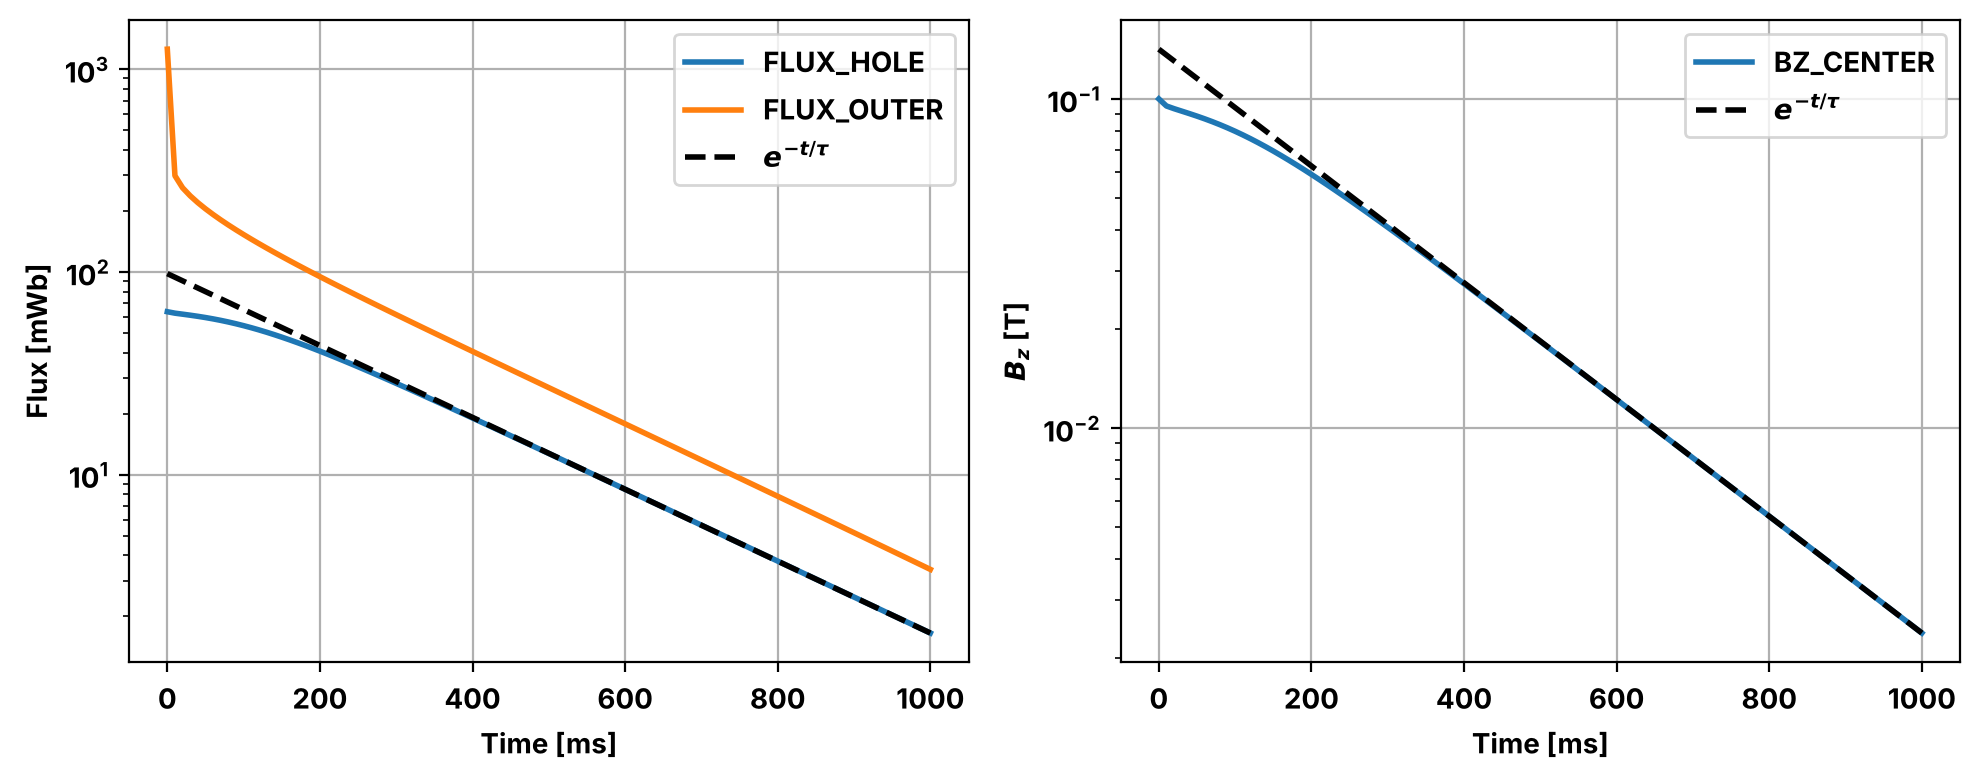

In [10]:
sensor_hist = tc_model.load_history('floops.hist')
time = sensor_hist['time']
tau_eff = dt/np.log(1.0+dt/tau_eigs[0])
flux = sensor_hist['FLUX_HOLE']
tau_fit = -(time[-1]-time[-11])/np.log(flux[-1]/flux[-11])
print('Late-time decay of hole flux = {0:.2f} ms (expected {1:.2f} ms)'.format(tau_fit*1.E3, tau_eff*1.E3))

fig, ax = plt.subplots(1,2,figsize=(10,4),tight_layout=True)
for name in ('FLUX_HOLE', 'FLUX_OUTER'):
    ax[0].semilogy(time*1.E3, sensor_hist[name]*1.E3, label=name)
ax[0].semilogy(time*1.E3, flux[-1]*np.exp(-(time-time[-1])/tau_eff)*1.E3, 'k--', label=r'$e^{-t/\tau}$')
ax[0].set_ylabel('Flux [mWb]')
ax[1].semilogy(time*1.E3, sensor_hist['BZ_CENTER'], label='BZ_CENTER')
ax[1].semilogy(time*1.E3, sensor_hist['BZ_CENTER'][-1]*np.exp(-(time-time[-1])/tau_eff), 'k--', label=r'$e^{-t/\tau}$')
ax[1].set_ylabel('$B_z$ [T]')
for ax_tmp in ax:
    ax_tmp.grid(True)
    ax_tmp.legend()
    ax_tmp.set_xlabel('Time [ms]')

## Visualization in ParaView
As for \ref doc_thickcurr_slab_ex, plot files are produced for the time-dependent fields in the run directory and for the eigenmodes in the `eigs` subdirectory. The current density (`J`) shows the toroidal eddy currents induced in the torus by the removal of the vertical field.

In [11]:
tc_model.plot_td(plot_freq=5)
td_plot, eig_plot = tc_model.build_XDMF()


  Starting ThickCurr post-processing
    thickcurr_00000.rst: t =   0.00000E+00


    thickcurr_00005.rst: t =   5.00000E-02


    thickcurr_00010.rst: t =   1.00000E-01


    thickcurr_00015.rst: t =   1.50000E-01


    thickcurr_00020.rst: t =   2.00000E-01


    thickcurr_00025.rst: t =   2.50000E-01


... (12 outputs left out)

    thickcurr_00090.rst: t =   9.00000E-01


    thickcurr_00095.rst: t =   9.50000E-01


    thickcurr_00100.rst: t =   1.00000E+00



Creating output files: oft_xdmf.XXXX.h5
  Removing old Xdmf files
    Removed 0 files
  Found Group: thickcurr
    Found Mesh: smesh
      # of blocks: 1
    Found Mesh: vmesh
      # of blocks: 1

Creating output files: oft_xdmf.XXXX.h5
  Removing old Xdmf files
    Removed 0 files
  Found Group: thickcurr_eigs
    Found Mesh: smesh
      # of blocks: 1
    Found Mesh: vmesh
      # of blocks: 1


## Running in parallel
The same calls can be used in a python script that is run with MPI (eg. `mpirun -np 4 python run_torus.py`), where the mesh is automatically decomposed across processes. In this case only the head process (`myOFT.head_proc`) should read output files or produce plots, and all processes must make the same calls to ThickCurr.

\note With MPI the block-Jacobi preconditioners only factor the portion of each matrix local to each process. For the coarse level of the p-multigrid preconditioner used here this removes the global coupling provided by the direct solve and convergence degrades significantly (eg. ~300 iterations per step on 2 processes). Increasing the number of GMRES iterations on the coarse level (eg. `<its>30</its>` and `<nrits>30</nrits>` in the `coarse` element) recovers convergence similar to the serial case (~10-20 iterations per step), but on this relatively small problem parallel runs are not faster than serial ones. A distributed direct solver for the coarse level (eg. via PETSc) is required for efficient scaling.